# Detección de Peligros Industriales — Entrega Final

### Inteligencia Artificial II

Esta versión realiza una comparación **justa y reproducible** entre cuatro detectores:

- **YOLO11n**
- **YOLO11s**
- **YOLO26n**
- **YOLO26s**

### Cambio metodológico principal

El `train` original del dataset se divide de forma determinista en:

- **80 % entrenamiento**
- **20 % validación**

La carpeta `valid` original se conserva como **holdout final** y se usa únicamente
como **test** después del entrenamiento.

> Esto evita utilizar el mismo conjunto para early stopping/selección del checkpoint
> y para reportar el resultado final de esta nueva etapa.

### Flujo
Dataset → split train/val → fine-tuning → evaluación en test → comparación global →
análisis por clase → comparación visual → W&B → mejor `best.pt`.

## 1. Configuración del entorno

### Antes de ejecutar en Kaggle

1. Activar **GPU**.
2. Activar **Internet**.
3. Agregar como Input el dataset **Industrial Hazards Detection**.
4. Crear el Secret `WANDB_API_KEY`.

Se fija la misma semilla para todos los modelos.

In [1]:
# Versión con soporte para YOLO26.
!pip install -q "ultralytics>=8.4.197" wandb

import os
import random
import shutil
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import torch
import wandb

from PIL import Image, ImageDraw, ImageFont
from ultralytics import YOLO, settings
from kaggle_secrets import UserSecretsClient

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = 0 if torch.cuda.is_available() else "cpu"

print("Dispositivo:", "GPU" if torch.cuda.is_available() else "CPU")
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

import ultralytics
print("Ultralytics:", ultralytics.__version__)
print("W&B:", wandb.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Dispositivo: GPU
GPU: Tesla T4
Ultralytics: 8.4.215
W&B: 0.28.1


## 2. W&B grupal

Los nuevos experimentos se registran en el **team grupal** y en el proyecto común.

Si el slug del team cambia, solo se modifica `WANDB_ENTITY`.

In [2]:
WANDB_ENTITY = "proyectoIAII"
WANDB_PROJECT = "industrial-hazard-detection"

secrets = UserSecretsClient()
WANDB_API_KEY = secrets.get_secret("WANDB_API_KEY")

if not WANDB_API_KEY:
    raise RuntimeError(
        "No se encontró WANDB_API_KEY. "
        "Créalo en Kaggle > Add-ons > Secrets."
    )

os.environ["WANDB_API_KEY"] = WANDB_API_KEY
os.environ["WANDB_ENTITY"] = WANDB_ENTITY
os.environ["WANDB_PROJECT"] = WANDB_PROJECT

wandb.login(key=WANDB_API_KEY, relogin=True)

settings.update({
    "wandb": True,
    "tensorboard": False,
    "mlflow": False,
    "clearml": False,
    "comet": False,
})

print("W&B conectado correctamente.")
print("Entity:", WANDB_ENTITY)
print("Project:", WANDB_PROJECT)

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: anfebefo (proyectoIAII) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


W&B conectado correctamente.
Entity: proyectoIAII
Project: industrial-hazard-detection


## 3. Dataset original

Se parte del mismo dataset utilizado en la segunda entrega:

- **1.343 imágenes**
- **5 clases**
- `train` original: **1.074 imágenes**
- `valid` original: **269 imágenes**

La carpeta `valid` original no se usa durante el entrenamiento de esta nueva etapa:
queda reservada como **test final**.

In [3]:
DATASET_ROOT = Path(
    "/kaggle/input/datasets/vigneshnachu/industrial-hazards-detection"
)

DATA_YAML = DATASET_ROOT / "data.yaml"

ORIGINAL_TRAIN_IMAGES = DATASET_ROOT / "train/images"
ORIGINAL_TRAIN_LABELS = DATASET_ROOT / "train/labels"

# Se reservará como TEST.
TEST_IMAGES = DATASET_ROOT / "valid/images"
TEST_LABELS = DATASET_ROOT / "valid/labels"

with open(DATA_YAML, "r") as f:
    data_cfg = yaml.safe_load(f)

raw_names = data_cfg["names"]

# Ultralytics puede guardar names como lista o diccionario.
if isinstance(raw_names, dict):
    class_names = [raw_names[i] for i in sorted(raw_names)]
else:
    class_names = list(raw_names)

print("Train original:", len(list(ORIGINAL_TRAIN_IMAGES.glob("*"))))
print("Test reservado:", len(list(TEST_IMAGES.glob("*"))))
print("Clases:", class_names)

Train original: 1074
Test reservado: 269
Clases: ['chemical hazard', 'fire', 'no helmet', 'smoke', 'water leak']


## 4. Crear split 80/20 a partir del train original

El split se realiza una sola vez con `seed=42`.

- **80 %** → train
- **20 %** → validation
- `valid` original → test

Se copian únicamente las imágenes que tienen su archivo de etiqueta correspondiente.

In [4]:
SPLIT_ROOT = Path("/kaggle/working/industrial_hazards_split")

TRAIN_IMAGES = SPLIT_ROOT / "train/images"
TRAIN_LABELS = SPLIT_ROOT / "train/labels"
VAL_IMAGES = SPLIT_ROOT / "val/images"
VAL_LABELS = SPLIT_ROOT / "val/labels"

for folder in [TRAIN_IMAGES, TRAIN_LABELS, VAL_IMAGES, VAL_LABELS]:
    folder.mkdir(parents=True, exist_ok=True)

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

original_images = sorted([
    p for p in ORIGINAL_TRAIN_IMAGES.iterdir()
    if p.suffix.lower() in image_extensions
    and (ORIGINAL_TRAIN_LABELS / f"{p.stem}.txt").exists()
])

rng = random.Random(SEED)
rng.shuffle(original_images)

split_idx = int(len(original_images) * 0.80)

train_files = original_images[:split_idx]
val_files = original_images[split_idx:]

def copy_pairs(files, image_dst, label_dst):
    for img_path in files:
        label_path = ORIGINAL_TRAIN_LABELS / f"{img_path.stem}.txt"
        shutil.copy2(img_path, image_dst / img_path.name)
        shutil.copy2(label_path, label_dst / label_path.name)

copy_pairs(train_files, TRAIN_IMAGES, TRAIN_LABELS)
copy_pairs(val_files, VAL_IMAGES, VAL_LABELS)

print("Nuevo train:", len(train_files))
print("Nuevo val:", len(val_files))
print("Test final:", len([
    p for p in TEST_IMAGES.iterdir()
    if p.suffix.lower() in image_extensions
]))

Nuevo train: 859
Nuevo val: 215
Test final: 269


### 4.1 Verificación del split

Se comprueba que las tres particiones contienen ejemplos de las cinco clases.

> El conteo mostrado corresponde a **objetos anotados**, no al número de imágenes.

,Clase,Train,Val,Test
0,chemical hazard,283,57,57
1,fire,400,101,114
2,no helmet,696,164,261
3,smoke,727,174,205
4,water leak,116,34,41


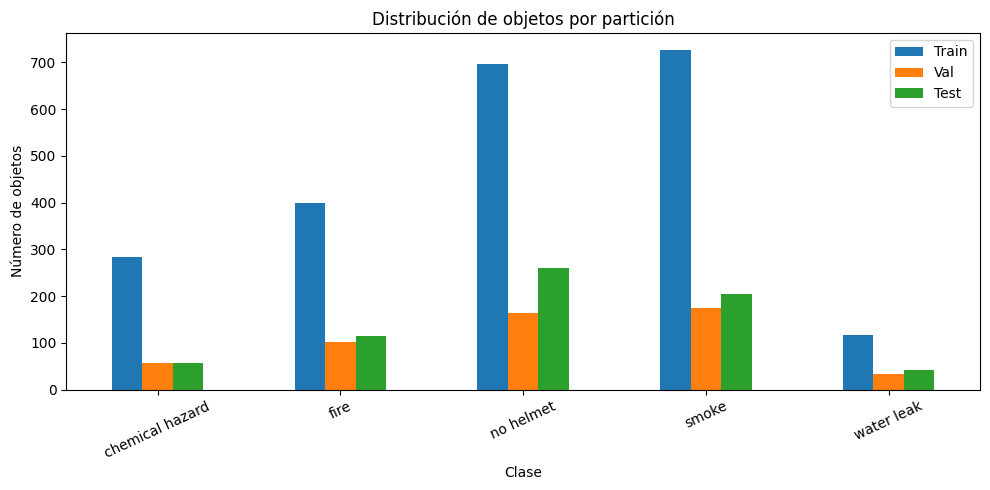

In [5]:
def count_objects(label_dir):
    counts = Counter()

    for label_file in Path(label_dir).glob("*.txt"):
        for line in label_file.read_text().splitlines():
            if line.strip():
                class_id = int(float(line.split()[0]))
                counts[class_id] += 1

    return counts

train_counts = count_objects(TRAIN_LABELS)
val_counts = count_objects(VAL_LABELS)
test_counts = count_objects(TEST_LABELS)

distribution_rows = []

for class_id, class_name in enumerate(class_names):
    distribution_rows.append({
        "Clase": class_name,
        "Train": train_counts.get(class_id, 0),
        "Val": val_counts.get(class_id, 0),
        "Test": test_counts.get(class_id, 0),
    })

distribution_df = pd.DataFrame(distribution_rows)

display(distribution_df)

assert all(distribution_df["Train"] > 0), "Falta una clase en train."
assert all(distribution_df["Val"] > 0), "Falta una clase en val."
assert all(distribution_df["Test"] > 0), "Falta una clase en test."

ax = distribution_df.set_index("Clase").plot(
    kind="bar",
    figsize=(10, 5)
)
ax.set_title("Distribución de objetos por partición")
ax.set_ylabel("Número de objetos")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## 5. YAML final

Este YAML incluye explícitamente `train`, `val` y `test`.

Durante `model.train()` se utilizan únicamente **train + val**.  
El `test` se evalúa después de seleccionar `best.pt`.

In [6]:
TRAINING_YAML = Path("/kaggle/working/industrial_hazards_final.yaml")

training_cfg = {
    "train": str(TRAIN_IMAGES),
    "val": str(VAL_IMAGES),
    "test": str(TEST_IMAGES),
    "nc": len(class_names),
    "names": class_names,
}

with open(TRAINING_YAML, "w") as f:
    yaml.safe_dump(training_cfg, f, sort_keys=False)

print(yaml.safe_dump(training_cfg, sort_keys=False))

OUTPUT_DIR = Path("/kaggle/working/industrial-hazard-final-fair")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

train: /kaggle/working/industrial_hazards_split/train/images
val: /kaggle/working/industrial_hazards_split/val/images
test: /kaggle/input/datasets/vigneshnachu/industrial-hazards-detection/valid/images
nc: 5
names:
- chemical hazard
- fire
- no helmet
- smoke
- water leak



## 6. Configuración experimental común

Para que la comparación sea lo más justa posible, los cuatro modelos utilizan:

- pesos preentrenados;
- fine-tuning end-to-end;
- entrada `640 × 640`;
- AdamW;
- `lr0 = 0.001`;
- `weight_decay = 0.0005`;
- máximo 80 épocas;
- `batch = 16`;
- early stopping con paciencia 15;
- misma semilla;
- exactamente el mismo train/val/test.

La diferencia principal será la arquitectura y escala de cada modelo.

In [7]:
COMMON_CONFIG = {
    "epochs": 80,
    "imgsz": 640,
    "batch": 16,
    "patience": 15,
    "optimizer": "AdamW",
    "lr0": 0.001,
    "weight_decay": 0.0005,
    "seed": SEED,
}

COMMON_CONFIG

{'epochs': 80,
 'imgsz': 640,
 'batch': 16,
 'patience': 15,
 'optimizer': 'AdamW',
 'lr0': 0.001,
 'weight_decay': 0.0005,
 'seed': 42}

## 7. Función única de entrenamiento y evaluación

Cada modelo:

1. carga pesos preentrenados;
2. realiza fine-tuning con el nuevo `train`;
3. usa el nuevo `val` para early stopping;
4. carga `best.pt`;
5. evalúa **una sola vez** sobre `test`;
6. registra métricas, resultados por clase y checkpoint en W&B.

In [8]:
def train_and_test(weights, run_name):
    print("\n" + "=" * 70)
    print("INICIANDO:", run_name)
    print("=" * 70)

    run = wandb.init(
        entity=WANDB_ENTITY,
        project=WANDB_PROJECT,
        name=run_name,
        job_type="final-fair-comparison",
        reinit=True,
        config={
            **COMMON_CONFIG,
            "weights": weights,
            "dataset": "Industrial Hazards Detection",
            "train_split": "80% del train original",
            "val_split": "20% del train original",
            "test_split": "valid original",
            "stage": "entrega-final",
        }
    )

    model = YOLO(weights)

    model.train(
        data=str(TRAINING_YAML),
        epochs=COMMON_CONFIG["epochs"],
        imgsz=COMMON_CONFIG["imgsz"],
        batch=COMMON_CONFIG["batch"],
        patience=COMMON_CONFIG["patience"],
        optimizer=COMMON_CONFIG["optimizer"],
        lr0=COMMON_CONFIG["lr0"],
        weight_decay=COMMON_CONFIG["weight_decay"],
        pretrained=True,
        seed=COMMON_CONFIG["seed"],
        device=DEVICE,
        workers=4,
        plots=True,
        save=True,
        project=str(OUTPUT_DIR),
        name=run_name,
        exist_ok=True,
    )

    best_checkpoint = OUTPUT_DIR / run_name / "weights" / "best.pt"

    if not best_checkpoint.exists():
        wandb.finish()
        raise FileNotFoundError(f"No se encontró {best_checkpoint}")

    best_model = YOLO(str(best_checkpoint))

    # Evaluación FINAL: solo test.
    metrics = best_model.val(
        data=str(TRAINING_YAML),
        split="test",
        imgsz=640,
        plots=True,
        verbose=False,
    )

    params_m = sum(p.numel() for p in best_model.model.parameters()) / 1e6
    checkpoint_mb = best_checkpoint.stat().st_size / (1024 ** 2)
    inference_ms = float(metrics.speed.get("inference", np.nan))

    summary = {
        "Modelo": run_name,
        "Pesos": weights,
        "Precision_test": float(metrics.box.mp),
        "Recall_test": float(metrics.box.mr),
        "mAP50_test": float(metrics.box.map50),
        "mAP50-95_test": float(metrics.box.map),
        "Inferencia_ms_img": inference_ms,
        "Parametros_M": params_m,
        "Checkpoint_MB": checkpoint_mb,
    }

    class_maps = np.asarray(metrics.box.maps)

    per_class_rows = []
    for class_id, class_name in enumerate(class_names):
        per_class_rows.append({
            "Modelo": run_name,
            "Clase": class_name,
            "mAP50-95_test": float(class_maps[class_id]),
        })

    class_df = pd.DataFrame(per_class_rows)

    wandb.log({
        "test/global_metrics": wandb.Table(
            dataframe=pd.DataFrame([summary])
        ),
        "test/per_class_metrics": wandb.Table(
            dataframe=class_df
        ),
        "data/split_distribution": wandb.Table(
            dataframe=distribution_df
        ),
    })

    for key, value in summary.items():
        if key not in {"Modelo", "Pesos"}:
            run.summary[key] = value

    artifact = wandb.Artifact(
        name=f"{run_name}-best",
        type="model",
        metadata={
            "architecture": weights,
            "test_mAP50-95": summary["mAP50-95_test"],
            "classes": class_names,
            "seed": SEED,
        },
    )

    artifact.add_file(str(best_checkpoint))
    wandb.log_artifact(artifact)

    wandb.finish()

    return summary, class_df, best_checkpoint

## 8. Entrenamientos

Se ejecutan secuencialmente para aprovechar una sola GPU de Kaggle.

### 8.1 YOLO11n

In [9]:
yolo11n_summary, yolo11n_classes, yolo11n_best = train_and_test(
    "yolo11n.pt",
    "final_yolo11n_fair"
)

display(pd.DataFrame([yolo11n_summary]))


INICIANDO: final_yolo11n_fair


wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261117_030223-g45yycs3
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run final_yolo11n_fair
wandb: ⭐️ View project at https://wandb.ai/proyectoIAII/industrial-hazard-detection
wandb: 🚀 View run at https://wandb.ai/proyectoIAII/industrial-hazard-detection/runs/g45yycs3


Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/industrial_hazards_final.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=final_yolo11n_fair, nbs=64, nms=None, opse

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/80      2.83G      1.981      2.571      1.994         54        640: 100% ━━━━━━━━━━━━ 54/54 8.6it/s 6.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 5.5it/s 1.3s
                   all        215        530      0.196      0.262      0.123     0.0407

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/80      2.83G      1.921      2.418      1.942         65        640: 100% ━━━━━━━━━━━━ 54/54 8.6it/s 6.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 6.1it/s 1.1s
                   all        215        530      0.174      0.296      0.159     0.0585

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/80      2.83G      1.872      2.334      1.933         47        640: 100% ━━━━━━━━━━━━ 54/54 

wandb: uploading artifact run-g45yycs3-testglobal_metrics-_HCbWA; uploading artifact run-g45yycs3-testper_class_metrics-BbV_WA; uploading artifact run-g45yycs3-datasplit_distribution-4tHxAA; updating run metadata; uploading artifact final_yolo11n_fair-best
wandb: uploading artifact run-g45yycs3-testglobal_metrics-_HCbWA; uploading artifact run-g45yycs3-testper_class_metrics-BbV_WA; uploading artifact run-g45yycs3-datasplit_distribution-4tHxAA; uploading artifact final_yolo11n_fair-best
wandb: uploading wandb-summary.json; uploading config.yaml; uploading media/table/test/global_metrics_82_29b5665cc747830e8e90.table.json; uploading media/table/test/per_class_metrics_82_4599a08c9174798ecbc1.table.json; uploading media/table/data/split_distribution_82_3933cd134a2362c42cbd.table.json (+ 1 more)
wandb: 
wandb: Run history:
wandb:                epoch ▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▄▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇███
wandb:               lr/pg0 ▆█████▇▇▇▇▇▇▆▆▆▆▆▅▅▅▅▅▅▅▄▄▃▃▃▃▃▂▂▂▂▂▁▁▁▁
wandb:               lr/pg1 ▃▆██

,Modelo,Pesos,Precision_test,Recall_test,mAP50_test,mAP50-95_test,Inferencia_ms_img,Parametros_M,Checkpoint_MB
0,final_yolo11n_fair,yolo11n.pt,0.640998,0.659919,0.66035,0.333888,4.7078,2.605855,5.256189


### 8.2 YOLO11s

In [10]:
yolo11s_summary, yolo11s_classes, yolo11s_best = train_and_test(
    "yolo11s.pt",
    "final_yolo11s_fair"
)

display(pd.DataFrame([yolo11s_summary]))


INICIANDO: final_yolo11s_fair


wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261117_031408-tw9z47ji
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run final_yolo11s_fair
wandb: ⭐️ View project at https://wandb.ai/proyectoIAII/industrial-hazard-detection
wandb: 🚀 View run at https://wandb.ai/proyectoIAII/industrial-hazard-detection/runs/tw9z47ji


Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/industrial_hazards_final.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=final_yolo11s_fair, nbs=64, nms=None, opse

wandb: uploading artifact run-tw9z47ji-testglobal_metrics-3y-aQw; uploading artifact run-tw9z47ji-testper_class_metrics-9wlOzg; uploading artifact run-tw9z47ji-datasplit_distribution--097QA; updating run metadata; uploading artifact final_yolo11s_fair-best
wandb: uploading artifact run-tw9z47ji-testglobal_metrics-3y-aQw; uploading artifact run-tw9z47ji-testper_class_metrics-9wlOzg; uploading artifact run-tw9z47ji-datasplit_distribution--097QA; uploading artifact final_yolo11s_fair-best
wandb: uploading artifact final_yolo11s_fair-best
wandb: 
wandb: Run history:
wandb:                epoch ▁▁▁▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇███
wandb:               lr/pg0 ▂▅███▇▇▇▇▇▇▆▆▆▆▆▆▅▅▅▅▅▄▄▄▄▄▃▃▃▃▃▃▃▂▂▂▁▁▁
wandb:               lr/pg1 ▅████▇▇▇▇▇▆▆▆▆▆▆▆▅▅▅▅▄▄▄▄▄▃▃▃▃▃▃▂▂▂▂▂▁▁▁
wandb:               lr/pg2 █▅▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:     metrics/mAP50(B) ▁▂▁▃▂▄▄▄▄▅▅▅▅▅▅▆▆▆▅▆▆▇▇▇▇▇▇▇▇▇██▇█▇█████
wandb:  metrics/mAP50-95(B) ▁▁▁▂▂▃▄▃▃▄▄▅▅▄▄▅▅▄▆▆▆▆▆▇▇▆▇▇▇▇███▇█▇████
wandb: metrics/pr

,Modelo,Pesos,Precision_test,Recall_test,mAP50_test,mAP50-95_test,Inferencia_ms_img,Parametros_M,Checkpoint_MB
0,final_yolo11s_fair,yolo11s.pt,0.68136,0.585926,0.605136,0.30818,12.269989,9.429727,18.294519


### 8.3 YOLO26n

In [11]:
yolo26n_summary, yolo26n_classes, yolo26n_best = train_and_test(
    "yolo26n.pt",
    "final_yolo26n_fair"
)

display(pd.DataFrame([yolo26n_summary]))


INICIANDO: final_yolo26n_fair


wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261117_032912-k60esrmz
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run final_yolo26n_fair
wandb: ⭐️ View project at https://wandb.ai/proyectoIAII/industrial-hazard-detection
wandb: 🚀 View run at https://wandb.ai/proyectoIAII/industrial-hazard-detection/runs/k60esrmz


Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/industrial_hazards_final.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=final_yolo26n_fair, nbs=64, nms=None, opse

wandb: uploading artifact run-k60esrmz-testglobal_metrics-1YMS3A; uploading artifact run-k60esrmz-testper_class_metrics-LXxMiQ; uploading artifact run-k60esrmz-datasplit_distribution-Ey3acQ; updating run metadata; uploading artifact final_yolo26n_fair-best
wandb: uploading artifact run-k60esrmz-testglobal_metrics-1YMS3A; uploading artifact run-k60esrmz-testper_class_metrics-LXxMiQ; uploading artifact run-k60esrmz-datasplit_distribution-Ey3acQ; uploading artifact final_yolo26n_fair-best
wandb: 
wandb: Run history:
wandb:                epoch ▁▁▁▁▁▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇████
wandb:               lr/pg0 ▃█████▇▇▇▇▇▆▆▆▆▅▅▅▅▅▅▅▅▄▄▄▄▄▄▃▃▃▃▃▃▂▂▂▁▁
wandb:               lr/pg1 ▆████▇▇▇▇▇▇▇▆▆▆▆▆▆▅▅▅▅▄▄▄▄▄▄▃▃▃▂▂▂▂▂▂▁▁▁
wandb:               lr/pg2 █▅▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:     metrics/mAP50(B) ▁▄▅▄▅▆▇▇▇▇▇▇▇▇▇▇██▇██▇▇█████████████████
wandb:  metrics/mAP50-95(B) ▁▁▃▄▄▅▅▅▆▆▆▆▇▆▆▇▇▇▇▇▇▇▇▇▇▇▇▇█▇▇████▇▇▇██
wandb: metrics/precision(B) ▂▁▄▅▅▆▆▆▆▇▅▇▅▆▇▇█▇▇▇▇▇▆▇▇█▇▇▇▇▇▇▇▇▇▆▆▆▇

,Modelo,Pesos,Precision_test,Recall_test,mAP50_test,mAP50-95_test,Inferencia_ms_img,Parametros_M,Checkpoint_MB
0,final_yolo26n_fair,yolo26n.pt,0.742951,0.630309,0.658569,0.330838,4.897161,2.53583,5.207097


### 8.4 YOLO26s

In [12]:
yolo26s_summary, yolo26s_classes, yolo26s_best = train_and_test(
    "yolo26s.pt",
    "final_yolo26s_fair"
)

display(pd.DataFrame([yolo26s_summary]))


INICIANDO: final_yolo26s_fair


wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261117_034306-gaqgq9i0
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run final_yolo26s_fair
wandb: ⭐️ View project at https://wandb.ai/proyectoIAII/industrial-hazard-detection
wandb: 🚀 View run at https://wandb.ai/proyectoIAII/industrial-hazard-detection/runs/gaqgq9i0


Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/industrial_hazards_final.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=final_yolo26s_fair, nbs=64, nms=None, opse

wandb: uploading artifact run-gaqgq9i0-testglobal_metrics-gIPWsQ; uploading artifact run-gaqgq9i0-testper_class_metrics-wuUG5Q; uploading artifact run-gaqgq9i0-datasplit_distribution-V8ZuSA; updating run metadata; uploading artifact final_yolo26s_fair-best
wandb: uploading artifact run-gaqgq9i0-testglobal_metrics-gIPWsQ; uploading artifact run-gaqgq9i0-testper_class_metrics-wuUG5Q; uploading artifact run-gaqgq9i0-datasplit_distribution-V8ZuSA; uploading artifact final_yolo26s_fair-best
wandb: uploading artifact run-gaqgq9i0-datasplit_distribution-V8ZuSA; uploading artifact final_yolo26s_fair-best
wandb: uploading artifact final_yolo26s_fair-best
wandb: uploading history steps 53-53, summary, console lines 321-329
wandb: 
wandb: Run history:
wandb:                epoch ▁▁▁▁▂▂▂▂▂▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇█████
wandb:               lr/pg0 ▁▅███▇▇▇▇▇▇▆▆▆▆▆▆▆▅▅▅▅▅▅▄▄▄▄▄▃▃▃▃▃▃▂▂▂▂▂
wandb:               lr/pg1 ▁▅███▇▇▇▇▇▇▆▆▆▆▆▆▆▅▅▅▅▅▄▄▄▄▄▃▃▃▃▃▃▃▂▂▂▂▂
wandb:               lr/pg2 █▅▁▁▁▁▁▁▁▁▁▁▁▁

,Modelo,Pesos,Precision_test,Recall_test,mAP50_test,mAP50-95_test,Inferencia_ms_img,Parametros_M,Checkpoint_MB
0,final_yolo26s_fair,yolo26s.pt,0.747751,0.595196,0.641541,0.33187,12.790743,9.951734,19.377507


## 9. Comparación final sobre TEST

Todos los modelos de esta tabla fueron:

- entrenados con el mismo train;
- seleccionados con el mismo validation;
- evaluados sobre exactamente el mismo test.

Por tanto, esta es la comparación principal de la entrega final.

In [13]:
summaries = [
    yolo11n_summary,
    yolo11s_summary,
    yolo26n_summary,
    yolo26s_summary,
]

comparison_df = (
    pd.DataFrame(summaries)
    .sort_values("mAP50-95_test", ascending=False)
    .reset_index(drop=True)
)

display(
    comparison_df[
        [
            "Modelo",
            "Precision_test",
            "Recall_test",
            "mAP50_test",
            "mAP50-95_test",
            "Inferencia_ms_img",
            "Parametros_M",
            "Checkpoint_MB",
        ]
    ].round(4)
)

comparison_df.to_csv(
    "/kaggle/working/comparacion_final_test.csv",
    index=False,
)

,Modelo,Precision_test,Recall_test,mAP50_test,mAP50-95_test,Inferencia_ms_img,Parametros_M,Checkpoint_MB
0,final_yolo11n_fair,0.6410,0.6599,0.6603,0.3339,4.7078,2.6059,5.2562
1,final_yolo26s_fair,0.7478,0.5952,0.6415,0.3319,12.7907,9.9517,19.3775
2,final_yolo26n_fair,0.7430,0.6303,0.6586,0.3308,4.8972,2.5358,5.2071
3,final_yolo11s_fair,0.6814,0.5859,0.6051,0.3082,12.2700,9.4297,18.2945


### 9.1 Resultados por clase sobre TEST

In [14]:
per_class_df = pd.concat(
    [
        yolo11n_classes,
        yolo11s_classes,
        yolo26n_classes,
        yolo26s_classes,
    ],
    ignore_index=True,
)

per_class_pivot = per_class_df.pivot(
    index="Modelo",
    columns="Clase",
    values="mAP50-95_test",
)

display(per_class_pivot.round(4))

per_class_df.to_csv(
    "/kaggle/working/resultados_por_clase_test.csv",
    index=False,
)

Clase,chemical hazard,fire,no helmet,smoke,water leak
Modelo,,,,,
final_yolo11n_fair,0.2762,0.2708,0.4859,0.2669,0.3697
final_yolo11s_fair,0.2528,0.2358,0.4898,0.2411,0.3214
final_yolo26n_fair,0.2600,0.2831,0.4818,0.2607,0.3685
final_yolo26s_fair,0.3224,0.2609,0.4843,0.2610,0.3308


### 9.2 Gráfica comparativa global

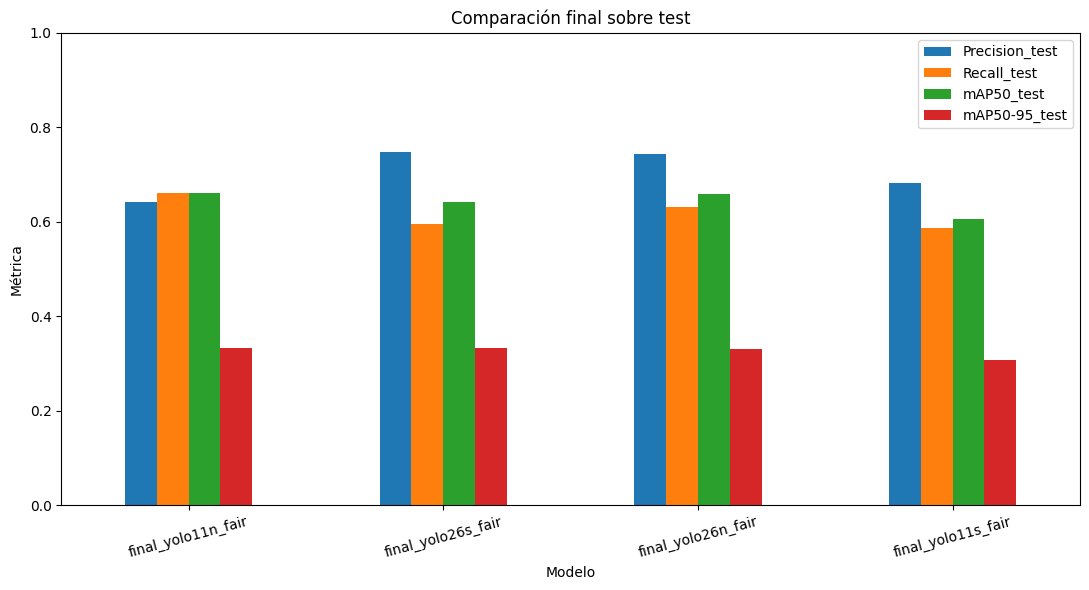

In [15]:
plot_df = comparison_df.set_index("Modelo")[
    ["Precision_test", "Recall_test", "mAP50_test", "mAP50-95_test"]
]

ax = plot_df.plot(
    kind="bar",
    figsize=(11, 6),
)

ax.set_title("Comparación final sobre test")
ax.set_ylabel("Métrica")
ax.set_ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 10. Registrar comparación final en W&B

In [16]:
run = wandb.init(
    entity=WANDB_ENTITY,
    project=WANDB_PROJECT,
    name="FINAL_comparacion_justa_test",
    job_type="final-evaluation",
    reinit=True,
)

wandb.log({
    "final/test_model_comparison": wandb.Table(dataframe=comparison_df),
    "final/test_per_class": wandb.Table(dataframe=per_class_df),
    "final/split_distribution": wandb.Table(dataframe=distribution_df),
})

best_row = comparison_df.iloc[0]

run.summary["best_model"] = best_row["Modelo"]
run.summary["best_test_mAP50-95"] = float(best_row["mAP50-95_test"])
run.summary["best_test_mAP50"] = float(best_row["mAP50_test"])
run.summary["best_test_recall"] = float(best_row["Recall_test"])

wandb.finish()

print("Comparación final registrada en W&B grupal.")

wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261117_035729-zub7xse0
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run FINAL_comparacion_justa_test
wandb: ⭐️ View project at https://wandb.ai/proyectoIAII/industrial-hazard-detection
wandb: 🚀 View run at https://wandb.ai/proyectoIAII/industrial-hazard-detection/runs/zub7xse0
wandb: updating run metadata; uploading artifact run-zub7xse0-finaltest_model_comparison-fYN8Pg; uploading artifact run-zub7xse0-finaltest_per_class--wG5iw; uploading artifact run-zub7xse0-finalsplit_distribution-W1dRXg; uploading summary
wandb: uploading artifact run-zub7xse0-finaltest_model_comparison-fYN8Pg; uploading artifact run-zub7xse0-finaltest_per_class--wG5iw; uploading artifact run-zub7xse0-finalsplit_distribution-W1dRXg
wandb: uploading artifact run-zub7xse0-finaltest_per_class--wG5iw
wandb: 
wandb: Run summary:
wandb:         best_model final_yolo11n_fair
wandb:    best_test

Comparación final registrada en W&B grupal.


## 11. Comparación visual sobre las MISMAS imágenes de test

Para facilitar la exposición se seleccionan las mismas imágenes y se muestran:

**Ground Truth | YOLO11n | YOLO11s | YOLO26n | YOLO26s**

No se reentrena ningún modelo en esta sección.

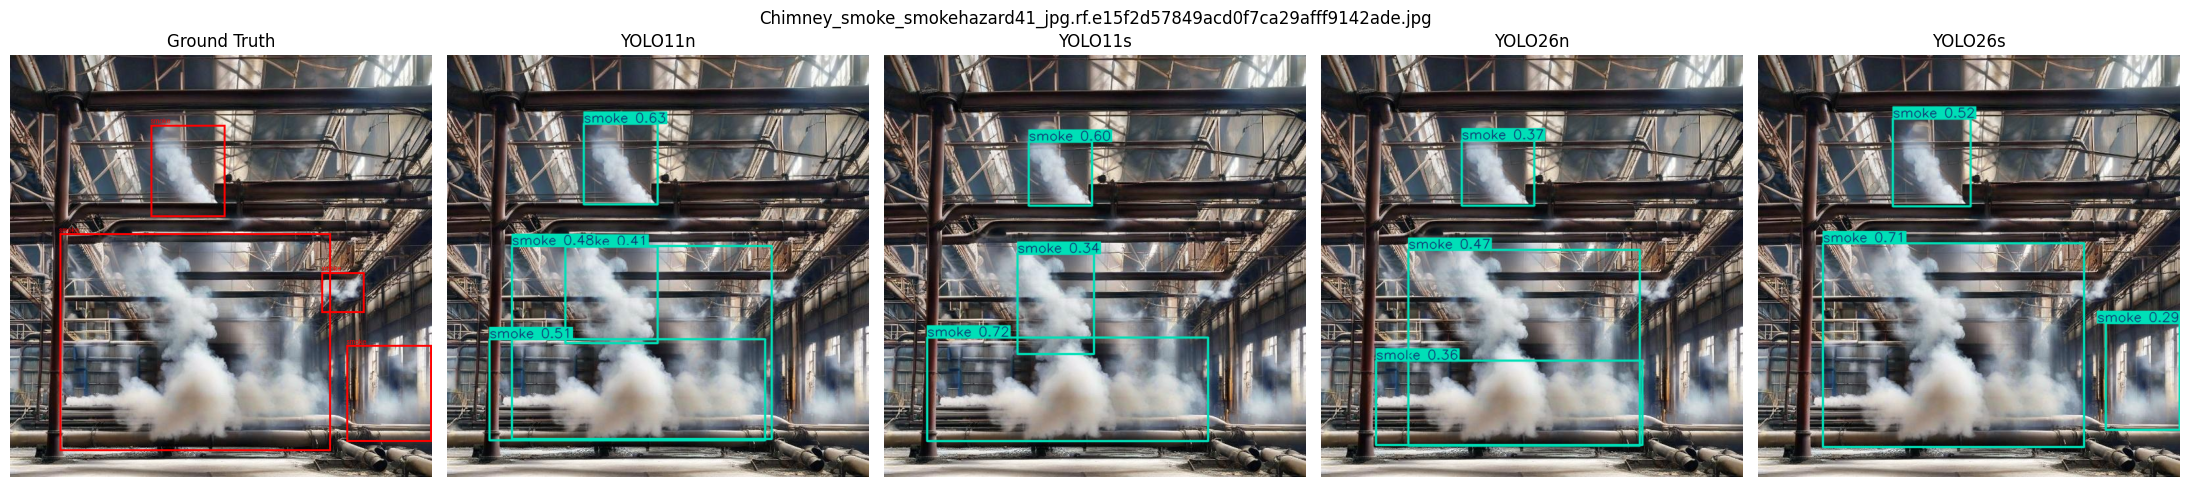

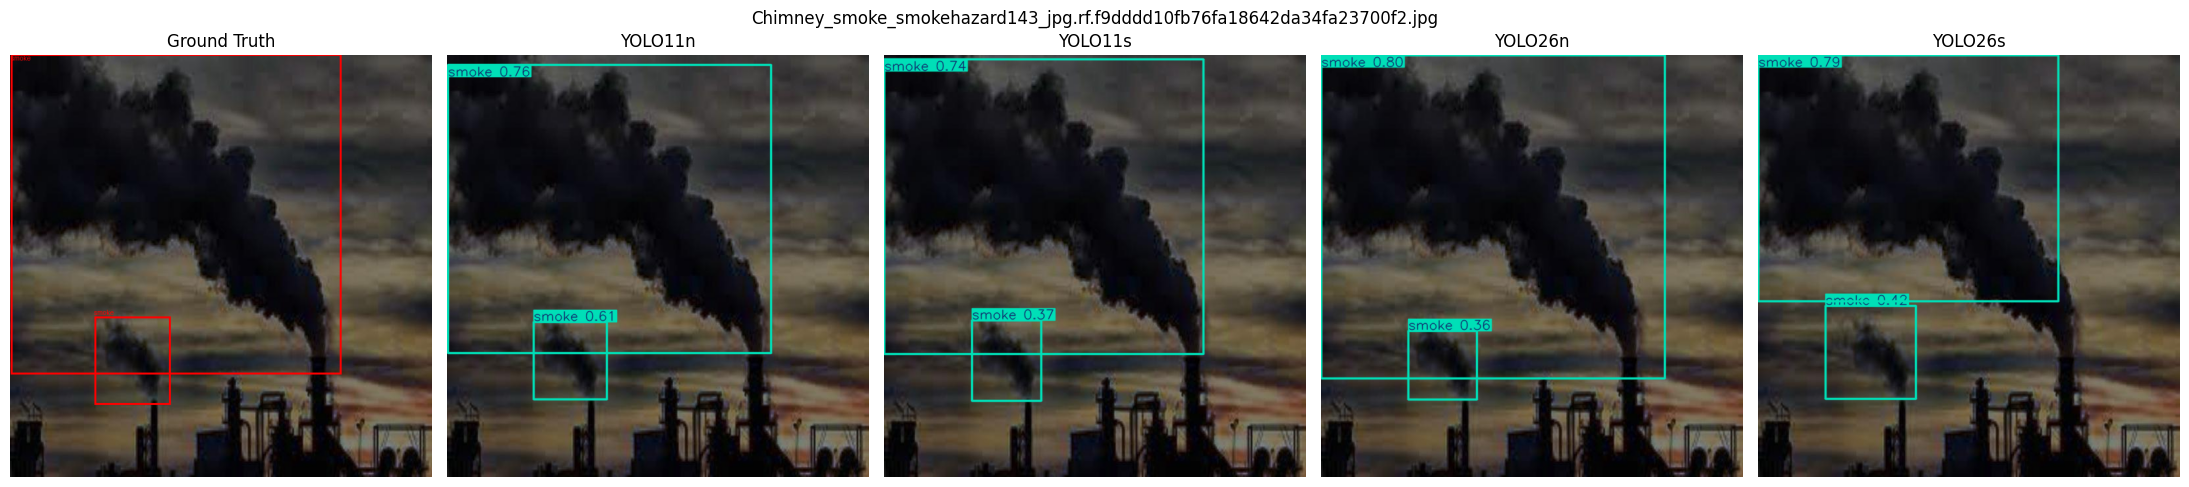

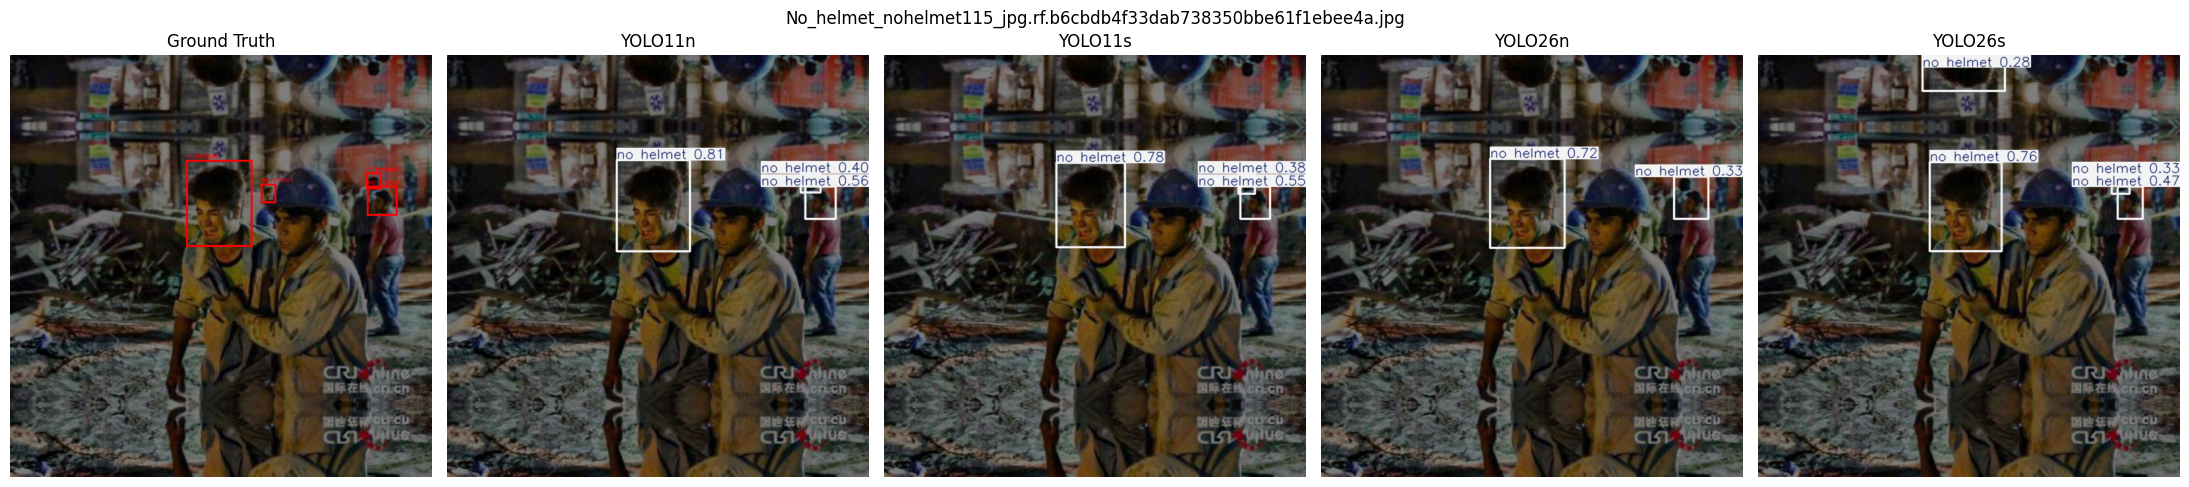

In [17]:
checkpoints = {
    "YOLO11n": yolo11n_best,
    "YOLO11s": yolo11s_best,
    "YOLO26n": yolo26n_best,
    "YOLO26s": yolo26s_best,
}

models = {
    name: YOLO(str(path))
    for name, path in checkpoints.items()
}

test_image_files = sorted([
    p for p in TEST_IMAGES.iterdir()
    if p.suffix.lower() in image_extensions
])

visual_samples = random.Random(SEED).sample(
    test_image_files,
    k=min(3, len(test_image_files))
)

def draw_ground_truth(img_path):
    image = Image.open(img_path).convert("RGB")
    draw = ImageDraw.Draw(image)

    label_path = TEST_LABELS / f"{img_path.stem}.txt"

    if label_path.exists():
        w, h = image.size

        for line in label_path.read_text().splitlines():
            if not line.strip():
                continue

            cls, xc, yc, bw, bh = map(float, line.split()[:5])
            cls = int(cls)

            x1 = (xc - bw / 2) * w
            y1 = (yc - bh / 2) * h
            x2 = (xc + bw / 2) * w
            y2 = (yc + bh / 2) * h

            draw.rectangle(
                [x1, y1, x2, y2],
                outline="red",
                width=3
            )
            draw.text(
                (x1, max(0, y1 - 12)),
                class_names[cls],
                fill="red"
            )

    return np.array(image)

for img_path in visual_samples:
    fig, axes = plt.subplots(1, 5, figsize=(22, 5))

    axes[0].imshow(draw_ground_truth(img_path))
    axes[0].set_title("Ground Truth")
    axes[0].axis("off")

    for ax, (model_name, detector) in zip(axes[1:], models.items()):
        pred = detector.predict(
            source=str(img_path),
            imgsz=640,
            conf=0.25,
            verbose=False,
        )[0]

        ax.imshow(pred.plot()[:, :, ::-1])
        ax.set_title(model_name)
        ax.axis("off")

    plt.suptitle(img_path.name)
    plt.tight_layout()
    plt.show()

## 12. Experimento extra — mejor YOLO26 con NMS vs end-to-end

Solo se ejecuta sobre el **mejor YOLO26 ya entrenado**.

No vuelve a entrenar.  
Permite analizar si la inferencia end-to-end sin NMS aporta ventajas de latencia
y qué costo tiene en las métricas.

In [18]:
best_yolo26 = max(
    [
        (yolo26n_summary["mAP50-95_test"], yolo26n_best, "YOLO26n"),
        (yolo26s_summary["mAP50-95_test"], yolo26s_best, "YOLO26s"),
    ],
    key=lambda x: x[0],
)

_, best_yolo26_checkpoint, best_yolo26_name = best_yolo26

model_yolo26_final = YOLO(str(best_yolo26_checkpoint))

metrics_nms = model_yolo26_final.val(
    data=str(TRAINING_YAML),
    split="test",
    imgsz=640,
    nms=True,
    verbose=False,
)

metrics_e2e = model_yolo26_final.val(
    data=str(TRAINING_YAML),
    split="test",
    imgsz=640,
    nms=False,
    verbose=False,
)

nms_comparison = pd.DataFrame([
    {
        "Modo": "Con NMS",
        "Precision": float(metrics_nms.box.mp),
        "Recall": float(metrics_nms.box.mr),
        "mAP50": float(metrics_nms.box.map50),
        "mAP50-95": float(metrics_nms.box.map),
        "Inferencia_ms_img": float(metrics_nms.speed.get("inference", np.nan)),
    },
    {
        "Modo": "End-to-end sin NMS",
        "Precision": float(metrics_e2e.box.mp),
        "Recall": float(metrics_e2e.box.mr),
        "mAP50": float(metrics_e2e.box.map50),
        "mAP50-95": float(metrics_e2e.box.map),
        "Inferencia_ms_img": float(metrics_e2e.speed.get("inference", np.nan)),
    },
])

print("YOLO26 evaluado:", best_yolo26_name)
display(nms_comparison.round(4))

nms_comparison.to_csv(
    "/kaggle/working/comparacion_nms_end_to_end.csv",
    index=False,
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,467,115 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.0 ms, read: 109.6±35.4 MB/s, size: 49.4 KB)
val: Scanning /kaggle/input/datasets/vigneshnachu/industrial-hazards-detection/valid/labels... 269 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 269/269 881.1it/s 0.3s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/vigneshnachu/industrial-hazards-detection/valid is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 3.3it/s 5.2s
                   all        269        678      0.748      0.595      0.642      0.332
Speed: 1.1ms preprocess, 12.3ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /kaggle/working/runs/detect/val-5
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO2

,Modo,Precision,Recall,mAP50,mAP50-95,Inferencia_ms_img
0,Con NMS,0.7478,0.5952,0.6415,0.3319,12.3421
1,End-to-end sin NMS,0.6818,0.5796,0.6008,0.3030,12.4449


## 13. Resumen final

Esta celda identifica automáticamente el mejor modelo según `mAP@50:95` sobre test.

Para una aplicación de alarma industrial también deben analizarse **Recall,
mAP@50 y latencia**, ya que una bounding box extremadamente precisa puede ser
menos crítica que detectar oportunamente el riesgo.

In [19]:
best = comparison_df.iloc[0]

print("=" * 60)
print("MEJOR MODELO SOBRE TEST")
print("=" * 60)

print("Modelo:", best["Modelo"])
print("Precision:", round(float(best["Precision_test"]), 4))
print("Recall:", round(float(best["Recall_test"]), 4))
print("mAP50:", round(float(best["mAP50_test"]), 4))
print("mAP50-95:", round(float(best["mAP50-95_test"]), 4))
print("Inferencia ms/img:", round(float(best["Inferencia_ms_img"]), 3))

print("\nArchivos finales:")
print("/kaggle/working/comparacion_final_test.csv")
print("/kaggle/working/resultados_por_clase_test.csv")
print("/kaggle/working/comparacion_nms_end_to_end.csv")
print("\nCheckpoints:")
for name, path in checkpoints.items():
    print(name, "->", path)

MEJOR MODELO SOBRE TEST
Modelo: final_yolo11n_fair
Precision: 0.641
Recall: 0.6599
mAP50: 0.6603
mAP50-95: 0.3339
Inferencia ms/img: 4.708

Archivos finales:
/kaggle/working/comparacion_final_test.csv
/kaggle/working/resultados_por_clase_test.csv
/kaggle/working/comparacion_nms_end_to_end.csv

Checkpoints:
YOLO11n -> /kaggle/working/industrial-hazard-final-fair/final_yolo11n_fair/weights/best.pt
YOLO11s -> /kaggle/working/industrial-hazard-final-fair/final_yolo11s_fair/weights/best.pt
YOLO26n -> /kaggle/working/industrial-hazard-final-fair/final_yolo26n_fair/weights/best.pt
YOLO26s -> /kaggle/working/industrial-hazard-final-fair/final_yolo26s_fair/weights/best.pt
